# EuroSAT Representation Benchmark

**Research question.** How do pretrained CNN and Transformer representations compare on EuroSAT when only 1, 5 or 10 labeled original images per class are available, and how does support-image augmentation change that comparison?

This notebook presents the dataset audit, experimental protocol and execution workflow. Development labels select settings; held-out query labels are reserved for evaluation. Smoke runs validate execution and are not final research results. Saved outputs reflect a prior execution; rerun to refresh them for your current runtime.

**Colab:** open `EuroSAT_Representation_Benchmark.ipynb`, choose a GPU runtime (T4 or L4), then run all cells. In VS Code, select **Colab → New Colab Server → GPU → Python 3 (ipykernel)**. This single notebook embeds the project modules and works in Colab or VS Code. For a local kernel, set `TARGET = 'local'`.


## 1. Runtime and execution scope

In [14]:
import os
import sys
import shutil
import subprocess
from pathlib import Path

TARGET = os.environ.get('EUROSAT_TARGET', 'colab_gpu')
MODE = os.environ.get('EUROSAT_MODE', 'smoke')  # Change to full after checking the workflow.
ASSIGNMENT = os.environ.get('EUROSAT_ASSIGNMENT', 'all')  # all or a backbone name from Parts A–D.
if TARGET not in {'colab_gpu', 'local'} or MODE not in {'smoke', 'full'}:
    raise ValueError('Choose TARGET colab_gpu/local and MODE smoke/full')
if TARGET == 'colab_gpu':
    if not Path('/content').is_dir():
        raise RuntimeError('Still using a local kernel. Select a Colab GPU server, then Run all.')
    command = shutil.which('nvidia-smi')
    gpu = subprocess.run([command, '--query-gpu=name', '--format=csv,noheader'],
                         capture_output=True, text=True) if command else None
    if gpu is None or gpu.returncode != 0 or not gpu.stdout.strip():
        raise RuntimeError('This server has no NVIDIA GPU. Create a GPU server, not a TPU/CPU server.')
    print('Colab GPU:', gpu.stdout.strip())
else:
    print('Intentional local run; no cloud GPU connection is being used.')
print('Experiment mode:', MODE)


Colab GPU: Tesla T4
Experiment mode: smoke


## 2. Environment and persistent storage

In [15]:
import importlib.util

requirements = {'torch': 'torch>=2.6,<3', 'torchvision': 'torchvision>=0.21,<1',
                'numpy': 'numpy>=1.26,<3', 'sklearn': 'scikit-learn>=1.4,<1.8',
                'PIL': 'Pillow>=10,<13', 'matplotlib': 'matplotlib>=3.8,<4',
                'pandas': 'pandas>=2.2,<3', 'seaborn': 'seaborn>=0.13,<0.14'}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing])
if TARGET == 'colab_gpu':
    from google.colab import drive
    drive.mount('/content/drive')
    # A shared Drive folder/shortcut can be used here after granting access to all teammates.
    drive_project = Path('/content/drive/MyDrive/ColabNotebooks/cs7643')
    previous_storage = drive_project / 'EuroSATLowData'
    default_storage = previous_storage if previous_storage.exists() else drive_project / 'EuroSATRepresentationBenchmark'
    STORAGE = Path(os.environ.get('EUROSAT_STORAGE', str(default_storage)))
    SCRATCH = Path('/content/eurosat-representation-benchmark')
else:
    current = Path.cwd()
    project = next((p for p in [current, *current.parents] if (p / 'pyproject.toml').exists()), current)
    STORAGE = Path(os.environ.get('EUROSAT_STORAGE', str(project)))
    SCRATCH = STORAGE / 'data/extracted'
STORAGE.mkdir(parents=True, exist_ok=True)
print('Persistent archive, features and results:', STORAGE)
print('Recreatable runtime-local image files:', SCRATCH)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persistent archive, features and results: /content/drive/MyDrive/ColabNotebooks/cs7643/EuroSATLowData
Recreatable runtime-local image files: /content/eurosat-low-data


## 3. Load project helpers

The following cells contain the actual implementation, grouped by responsibility. Run them in order to define the helpers; experiments start in section 7. No repository imports or encoded loader are required.


### 3.1. Presets and checkpoint identities

In [16]:
"""Experiment presets and immutable dataset/checkpoint identities."""
from dataclasses import dataclass, field

PIPELINE_VERSION = '1'
DATA_URL = ('https://huggingface.co/datasets/torchgeo/eurosat/resolve/'
            'c877bcd43f099cd0196738f714544e355477f3fd/EuroSAT.zip')
DATA_MD5 = 'c8fa014336c82ac7804f0398fcb19387'
DINO_REVISION = '7764ea0f912e53c92e82eb78a2a1631e92725fc8'
CLASSES = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial',
           'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
MODEL_IDS = {
    'resnet18': 'torchvision.ResNet18_Weights.IMAGENET1K_V1',
    'convnext_tiny': 'torchvision.ConvNeXt_Tiny_Weights.IMAGENET1K_V1',
    'vit_b_16': 'torchvision.ViT_B_16_Weights.IMAGENET1K_V1',
    'dinov2_vits14': 'facebookresearch/dinov2:' + DINO_REVISION + '/dinov2_vits14',
}
POLICIES = ['none', 'repeat', 'flip', 'rotation', 'translation', 'scale',
            'brightness_contrast', 'noise', 'blur', 'erasing']


@dataclass
class Config:
    mode: str = 'smoke'
    seed: int = 42
    models: list = field(default_factory=lambda: ['resnet18'])
    policies: list = field(default_factory=lambda: ['none', 'repeat', 'flip'])
    shots: list = field(default_factory=lambda: [1, 5, 10])
    trials: int = 1
    views: int = 1
    per_class_limit: int | None = 40
    batch_size: int = 32
    chunk_size: int = 256
    classifier_cs: list = field(default_factory=lambda: [0.1, 1.0, 10.0])

    @classmethod
    def full(cls):
        return cls(mode='full', models=list(MODEL_IDS), policies=POLICIES.copy(),
                   trials=20, views=4, per_class_limit=None)

    def validate(self):
        if self.mode not in {'smoke', 'full'}:
            raise ValueError('mode must be smoke or full')
        if not self.models or set(self.models) - MODEL_IDS.keys():
            raise ValueError('Choose supported models: ' + ', '.join(MODEL_IDS))
        if 'none' not in self.policies or set(self.policies) - set(POLICIES):
            raise ValueError('Policies must include none and contain supported names')
        if not self.shots or min(self.shots) < 1 or min(self.trials, self.views, self.batch_size, self.chunk_size) < 1:
            raise ValueError('Shot budgets, trials, views and batch/chunk sizes must be positive')
        if not self.classifier_cs or min(self.classifier_cs) <= 0:
            raise ValueError('Classifier C values must be positive')


### 3.2. Atomic checkpoints and persistent storage

In [17]:
"""Content-addressed artifacts and atomic checkpoint publication."""
from pathlib import Path
import hashlib
import json
import os
import tempfile
import numpy as np


def key(value):
    text = json.dumps({'pipeline': PIPELINE_VERSION, 'value': value},
                      sort_keys=True, separators=(',', ':'), allow_nan=False)
    return hashlib.sha256(text.encode()).hexdigest()


def digest_file(path, algorithm='sha256'):
    result = hashlib.new(algorithm)
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            result.update(block)
    return result.hexdigest()


def atomic(path, write):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, temporary = tempfile.mkstemp(prefix='.' + path.name, dir=path.parent)
    os.close(fd)
    try:
        write(Path(temporary))
        os.replace(temporary, path)
    finally:
        Path(temporary).unlink(missing_ok=True)


def write_json(path, value):
    atomic(path, lambda p: p.write_text(json.dumps(value, indent=2, sort_keys=True,
                                                   allow_nan=False) + '\n'))


def write_npz(path, **arrays):
    def save(temporary):
        with temporary.open('wb') as stream:
            np.savez_compressed(stream, **arrays)
    atomic(path, save)


def prepare_storage(storage):
    import torch
    storage = Path(storage)
    for name in ['data', 'cache/weights', 'cache/features', 'cache/experiments', 'outputs']:
        (storage / name).mkdir(parents=True, exist_ok=True)
    torch.hub.set_dir(str(storage / 'cache/weights/torch'))
    return storage


### 3.3. Hardware checks and software versions

In [18]:
"""Compute selection and software provenance."""
from pathlib import Path
import os
import numpy as np
import sklearn
import torch
import torchvision


def environment():
    return {'torch': str(torch.__version__), 'torchvision': str(torchvision.__version__),
            'numpy': np.__version__, 'sklearn': sklearn.__version__}


def check_device(target='colab_gpu'):
    if target not in {'colab_gpu', 'local'}:
        raise ValueError('target must be colab_gpu or local')
    if target == 'colab_gpu':
        if not Path('/content').is_dir() or not torch.cuda.is_available():
            raise RuntimeError('Select a Colab GPU server (T4 or L4), not a local/CPU/TPU '
                               'kernel. In VS Code: Select Another Kernel > Colab > '
                               'New Colab Server > GPU > Python 3 (ipykernel).')
        device = torch.device('cuda')
        label = torch.cuda.get_device_name(0)
    else:
        device = torch.device('cuda' if torch.cuda.is_available() else
                              'mps' if torch.backends.mps.is_available() else 'cpu')
        label = str(device)
    if device.type == 'cpu':
        torch.set_num_threads(min(4, os.cpu_count() or 1))
    if (torch.ones(1, device=device) + 1).cpu().item() != 2:
        raise RuntimeError('Device operation check failed')
    print(f'Compute: {label} [{device}] — device check passed', flush=True)
    return device


### 3.4. Support-image augmentation

In [19]:
"""Deterministic support-only augmentation policies."""
import random
from PIL import Image
import torch
from torchvision.transforms import functional as TF, InterpolationMode


def image_tensor(path, policy, seed):
    rng = random.Random(seed)
    with Image.open(path) as image:
        image = TF.resize(image.convert('RGB'), [224, 224], InterpolationMode.BILINEAR)
    if policy == 'flip':
        image = TF.hflip(image) if rng.random() < .5 else TF.vflip(image)
    elif policy == 'rotation':
        image = TF.rotate(image, rng.uniform(-30, 30), InterpolationMode.BILINEAR)
    elif policy == 'translation':
        image = TF.affine(image, 0, [rng.randint(-22, 22), rng.randint(-22, 22)], 1., [0., 0.],
                          InterpolationMode.BILINEAR)
    elif policy == 'scale':
        image = TF.affine(image, 0, [0, 0], rng.uniform(.8, 1.2), [0., 0.], InterpolationMode.BILINEAR)
    elif policy == 'brightness_contrast':
        image = TF.adjust_contrast(TF.adjust_brightness(image, rng.uniform(.7, 1.3)), rng.uniform(.7, 1.3))
    elif policy == 'blur':
        image = TF.gaussian_blur(image, [5, 5], [rng.uniform(.1, 1.5)] * 2)
    elif policy not in {'none', 'noise', 'erasing', 'cutout'}:
        raise ValueError('Unsupported image augmentation: ' + policy)
    tensor = TF.to_tensor(image)
    if policy == 'noise':
        generator = torch.Generator().manual_seed(seed)
        tensor = (tensor + torch.randn(tensor.shape, generator=generator) * .05).clamp(0, 1)
    elif policy in {'erasing', 'cutout'}:
        size = rng.randint(22, 67)
        top, left = rng.randrange(225 - size), rng.randrange(225 - size)
        tensor[:, top:top + size, left:left + size] = .5 if policy == 'erasing' else 0.
    return TF.normalize(tensor, [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])


### 3.5. Dataset acquisition, cleaning, splits and shot sampling

In [20]:
"""Verified EuroSAT acquisition, duplicate checking, partitions and paired trials."""
from pathlib import Path
import hashlib
import json
import random
import shutil
import urllib.request
import zipfile
from PIL import Image


def prepare_data(storage, scratch, config):
    """Persist one archive in Drive; read extracted images from fast runtime-local disk."""
    archive = storage / 'data/EuroSAT.zip'
    if not archive.exists():
        def download(temporary):
            print('Downloading EuroSAT RGB (~90 MB), once per storage folder...', flush=True)
            request = urllib.request.Request(DATA_URL, headers={'User-Agent': 'eurosat-representation-benchmark/0.1'})
            with urllib.request.urlopen(request, timeout=120) as response, temporary.open('wb') as stream:
                shutil.copyfileobj(response, stream)
            if digest_file(temporary, 'md5') != DATA_MD5:
                raise ValueError('Downloaded EuroSAT checksum does not match; rerun to retry')
        atomic(archive, download)
    if digest_file(archive, 'md5') != DATA_MD5:
        raise ValueError(f'EuroSAT archive is corrupt: {archive}')
    archive_id = digest_file(archive)
    raw = Path(scratch) / archive_id[:16]
    marker = raw / '.complete'
    if not marker.exists():
        raw.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as bundle:
            for name in bundle.namelist():
                if not (raw / name).resolve().is_relative_to(raw.resolve()):
                    raise ValueError('Archive contains an invalid path')
            bundle.extractall(raw)
        marker.write_text(archive_id)
    candidates = [raw] + sorted(p for p in raw.rglob('*') if p.is_dir())
    image_root = next((p for p in candidates if all((p / name).is_dir() for name in CLASSES)), None)
    if image_root is None:
        raise ValueError('EuroSAT class folders not found')
    manifest_path = storage / 'cache' / ('dataset-' + archive_id + '.json')
    if manifest_path.exists():
        manifest = json.loads(manifest_path.read_text())
    else:
        records, duplicates, seen = [], [], {}
        for label, name in enumerate(CLASSES):
            for path in sorted((image_root / name).glob('*.jpg')):
                with Image.open(path) as image:
                    rgb = image.convert('RGB')
                    fingerprint = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
                relative = path.relative_to(image_root).as_posix()
                if fingerprint in seen:
                    previous = seen[fingerprint]
                    if previous['label'] != label:
                        raise ValueError('Identical pixels have conflicting class labels')
                    duplicates.append({'kept': previous['path'], 'removed': relative})
                    continue
                record = {'path': relative, 'label': label, 'pixels_sha256': fingerprint}
                seen[fingerprint] = record
                records.append(record)
        manifest = {'archive_sha256': archive_id, 'records': records, 'duplicates': duplicates}
        write_json(manifest_path, manifest)
    records = manifest['records']
    if config.per_class_limit is not None:
        rng = random.Random(config.seed)
        records = [r for label in range(len(CLASSES)) for r in rng.sample(
            [r for r in records if r['label'] == label],
            min(config.per_class_limit, sum(r['label'] == label for r in records)))]
        records.sort(key=lambda r: r['path'])
    split = stratified_split(records, config.seed)
    dataset_id = key({'records': records, 'split': split})
    write_json(storage / 'cache' / ('split-' + dataset_id + '.json'),
               {'classes': CLASSES, 'records': records, 'split': split,
                'duplicate_images_removed': len(manifest['duplicates'])})
    counts = {name: len(indices) for name, indices in split.items()}
    print(f'Data: {len(records)} unique images, splits {counts}; '
          f'{len(manifest["duplicates"])} exact-pixel duplicates removed', flush=True)
    return image_root, records, split, dataset_id


def stratified_split(records, seed):
    split = {'support': [], 'dev': [], 'test': []}
    rng = random.Random(seed)
    for label in range(len(CLASSES)):
        indices = [i for i, row in enumerate(records) if row['label'] == label]
        rng.shuffle(indices)
        train, dev = int(len(indices) * .6), int(len(indices) * .2)
        if min(train, dev, len(indices) - train - dev) < 1:
            raise ValueError('Each class needs enough distinct images for three partitions')
        split['support'].extend(indices[:train])
        split['dev'].extend(indices[train:train + dev])
        split['test'].extend(indices[train + dev:])
    return split


def make_trials(records, split, config):
    trials = []
    maximum = max(config.shots)
    for trial in range(config.trials):
        rng = random.Random(config.seed + trial)
        selected = {}
        for label in range(len(CLASSES)):
            pool = [i for i in split['support'] if records[i]['label'] == label]
            if len(pool) < maximum:
                raise ValueError(f'Class {CLASSES[label]} has fewer than {maximum} support-pool images')
            # Shuffle the whole pool so changing the requested shot/view grid cannot
            # change the original support images in a corresponding trial.
            rng.shuffle(pool)
            selected[label] = pool[:maximum]
        trials.append({str(k): [i for label in range(len(CLASSES)) for i in selected[label][:k]]
                       for k in sorted(config.shots)})
    return trials


### 3.6. Frozen backbone adapters

In [21]:
"""Frozen pretrained CNN and Transformer representation adapters."""
import os
import torch
from torch import nn
from torchvision import models


def load_backbone(name, device):
    if name == 'resnet18':
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        model.fc = nn.Identity()
    elif name == 'convnext_tiny':
        model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        model.classifier[-1] = nn.Identity()
    elif name == 'vit_b_16':
        model = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)
        model.heads = nn.Identity()
    elif name == 'dinov2_vits14':
        # Official implementation + weights pinned to a specific source revision.
        os.environ['XFORMERS_DISABLED'] = '1'
        model = torch.hub.load('facebookresearch/dinov2:' + DINO_REVISION,
                               'dinov2_vits14', pretrained=True,
                               trust_repo=True, skip_validation=True)
    else:
        raise ValueError('Unknown backbone: ' + name)
    model.requires_grad_(False)
    return model.to(device).eval()


### 3.7. Batched feature extraction and caching

In [22]:
"""Chunked original/augmented feature extraction and recovery."""
import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset


class Images(Dataset):
    def __init__(self, root, records, items, policy, seed):
        self.root, self.records, self.items = root, records, items
        self.policy, self.seed = policy, seed

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        image_id, view = self.items[index]
        record = self.records[image_id]
        # Image/view seeds are shared across backbones and independent of batch/chunk order.
        seed = int(key([self.seed, record['pixels_sha256'], self.policy, view])[:15], 16)
        return image_tensor(self.root / record['path'], self.policy, seed), record['label']


def extract(storage, root, records, dataset_id, model_name, model, device, items, policy, config):
    identity = {'dataset': dataset_id, 'checkpoint': MODEL_IDS[model_name],
                'preprocess': 'rgb-bilinear224-imagenet-normalization-v1',
                'policy': policy, 'seed': config.seed, 'versions': environment()}
    matrices, labels = [], []
    for start in range(0, len(items), config.chunk_size):
        chunk_items = items[start:start + config.chunk_size]
        path = storage / 'cache/features' / (key({'config': identity, 'items': chunk_items}) + '.npz')
        if path.exists():
            with np.load(path, allow_pickle=False) as cached:
                features, targets = cached['features'], cached['labels']
            print(f'Cached {model_name}/{policy}: {start}:{start + len(chunk_items)}', flush=True)
        else:
            dataset = Images(root, records, chunk_items, policy, config.seed)
            loader = DataLoader(dataset, batch_size=config.batch_size, shuffle=False, num_workers=0)
            features, targets = [], []
            with torch.inference_mode():
                for images, y in loader:
                    features.append(model(images.to(device)).flatten(1).float().cpu().numpy())
                    targets.append(y.numpy())
            features, targets = np.concatenate(features), np.concatenate(targets)
            features /= np.maximum(np.linalg.norm(features, axis=1, keepdims=True), 1e-12)
            write_npz(path, features=features, labels=targets)
            print(f'Saved {model_name}/{policy}: {start}:{start + len(chunk_items)}', flush=True)
        matrices.append(features)
        labels.append(targets)
    if not matrices:
        raise ValueError('No images selected for feature extraction')
    return np.concatenate(matrices), np.concatenate(labels)


### 3.8. Classifier selection and paired metrics

In [23]:
"""Common classifier selection and paired held-out evaluation."""
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score


def score(labels, predictions):
    labels_all = list(range(len(CLASSES)))
    return {'accuracy': float(accuracy_score(labels, predictions)),
            'macro_f1': float(f1_score(labels, predictions, labels=labels_all, average='macro', zero_division=0)),
            'class_recall': recall_score(labels, predictions, labels=labels_all,
                                         average=None, zero_division=0).tolist(),
            'confusion_matrix': confusion_matrix(labels, predictions, labels=labels_all).tolist()}


def fit_classifier(x, y, dev_x, dev_y, config):
    best, selected, dev_accuracy = None, None, -1.
    for c in sorted(config.classifier_cs):
        # lbfgs uses multinomial loss for this ten-class task and L2 regularization.
        classifier = LogisticRegression(C=c, solver='lbfgs', max_iter=2000,
                                        random_state=config.seed)
        classifier.fit(x, y)
        accuracy = classifier.score(dev_x, dev_y)
        if accuracy > dev_accuracy:
            best, selected, dev_accuracy = classifier, c, float(accuracy)
    return best, selected, dev_accuracy


def summarize(rows):
    baseline = {(r['model'], r['shots'], r['trial']): r['test']['accuracy']
                for r in rows if r['policy'] == 'none'}
    groups = sorted({(r['model'], r['policy'], r['shots']) for r in rows})
    summary = []
    for model, policy, shots in groups:
        group = [r for r in rows if (r['model'], r['policy'], r['shots']) == (model, policy, shots)]
        scores = [r['test']['accuracy'] for r in group]
        gains = [r['test']['accuracy'] - baseline[model, shots, r['trial']] for r in group]
        summary.append({'model': model, 'policy': policy, 'shots': shots, 'trials': len(group),
                        'accuracy': float(np.mean(scores)), 'accuracy_std': float(np.std(scores)),
                        'macro_f1': float(np.mean([r['test']['macro_f1'] for r in group])),
                        'paired_gain_percentage_points': float(np.mean(gains) * 100),
                        'dev_accuracy': float(np.mean([r['dev_accuracy'] for r in group]))})
    return summary


### 3.9. Run and resume experiments

In [24]:
"""Experiment orchestration; implementation lives in focused modules."""
from dataclasses import asdict
from datetime import datetime, timezone
import csv
import io
import json
import time
import numpy as np
import torch


def run(config, storage, scratch, target='colab_gpu'):
    config.validate()
    device = check_device(target)
    storage = prepare_storage(storage)
    root, records, split, dataset_id = prepare_data(storage, scratch, config)
    trials = make_trials(records, split, config)
    manifest = {'config': asdict(config), 'dataset': dataset_id, 'versions': environment(),
                'trials': trials, 'checkpoints': {m: MODEL_IDS[m] for m in config.models}}
    experiment = key(manifest)
    directory = storage / 'cache/experiments' / experiment
    directory.mkdir(parents=True, exist_ok=True)
    write_json(directory / 'manifest.json', manifest)
    hardware = (torch.cuda.get_device_name(0) if device.type == 'cuda'
                else 'Apple GPU (MPS)' if device.type == 'mps' else 'CPU')
    write_json(directory / f'execution-{time.time_ns()}.json',
               {'utc': datetime.now(timezone.utc).isoformat(), 'device': str(device),
                'hardware': hardware, 'target': target, 'versions': environment()})
    labels_all = np.array([r['label'] for r in records])
    all_items = [(i, 0) for i in range(len(records))]
    support_union = sorted({i for trial in trials for indices in trial.values() for i in indices})
    rows = []
    for model_name in config.models:
        # A fully completed model is skipped without loading its weights or features.
        result_paths = [directory / (key([model_name, p, trial, k]) + '.json')
                        for p in config.policies for trial in range(config.trials) for k in config.shots]
        if all(p.exists() for p in result_paths):
            rows.extend(json.loads(p.read_text()) for p in result_paths)
            print('Completed results reused:', model_name, flush=True)
            continue
        started = time.perf_counter()
        model = load_backbone(model_name, device)
        original, _ = extract(storage, root, records, dataset_id, model_name, model,
                               device, all_items, 'none', config)
        feature_seconds = time.perf_counter() - started
        for policy in config.policies:
            paths = [directory / (key([model_name, policy, trial, k]) + '.json')
                     for trial in range(config.trials) for k in config.shots]
            if all(path.exists() for path in paths):
                rows.extend(json.loads(path.read_text()) for path in paths)
                continue
            augmented = None
            aug_map = {}
            if policy not in {'none', 'repeat'}:
                items = [(i, v) for i in support_union for v in range(config.views)]
                augmented, _ = extract(storage, root, records, dataset_id, model_name, model,
                                       device, items, policy, config)
                aug_map = {item: j for j, item in enumerate(items)}
            for trial_number, trial in enumerate(trials):
                for k in config.shots:
                    result_path = directory / (key([model_name, policy, trial_number, k]) + '.json')
                    if result_path.exists():
                        rows.append(json.loads(result_path.read_text()))
                        continue
                    indices = trial[str(k)]
                    x, y = original[indices], labels_all[indices]
                    if policy == 'repeat':
                        x, y = np.tile(x, (config.views + 1, 1)), np.tile(y, config.views + 1)
                    elif augmented is not None:
                        aug_indices = [aug_map[i, view] for i in indices for view in range(config.views)]
                        x = np.concatenate([x, augmented[aug_indices]])
                        y = np.concatenate([y, np.repeat(y, config.views)])
                    fit_started = time.perf_counter()
                    classifier, c, dev_accuracy = fit_classifier(
                        x, y, original[split['dev']], labels_all[split['dev']], config)
                    fit_seconds = time.perf_counter() - fit_started
                    result = {'model': model_name, 'policy': policy, 'shots': k, 'trial': trial_number,
                              'original_support_images': len(indices), 'classifier_rows': len(x),
                              'views': 0 if policy == 'none' else config.views, 'C': c,
                              'dev_accuracy': dev_accuracy,
                              'test': score(labels_all[split['test']], classifier.predict(original[split['test']])),
                              'classifier_fit_seconds': fit_seconds, 'original_feature_seconds': feature_seconds,
                              'parameter_count': sum(p.numel() for p in model.parameters())}
                    # Numeric classifier checkpoint: reloadable without pickle/code execution.
                    write_npz(result_path.with_suffix('.npz'), coef=classifier.coef_,
                              intercept=classifier.intercept_, classes=classifier.classes_)
                    write_json(result_path, result)
                    rows.append(result)
                    print(f'{model_name} {policy} {k}-shot trial {trial_number}: '
                          f'{result["test"]["accuracy"]:.3f}', flush=True)
        del model
        if device.type == 'cuda':
            torch.cuda.empty_cache()
        elif device.type == 'mps':
            torch.mps.empty_cache()
    summary = summarize(rows)
    output = storage / 'outputs' / experiment
    output.mkdir(parents=True, exist_ok=True)
    write_json(output / 'results.json', {'manifest': manifest, 'trials': rows, 'summary': summary})
    columns = ['model', 'policy', 'shots', 'trials', 'accuracy', 'accuracy_std', 'macro_f1',
               'paired_gain_percentage_points', 'dev_accuracy']
    stream = io.StringIO()
    writer = csv.DictWriter(stream, lineterminator='\n', fieldnames=columns)
    writer.writeheader()
    writer.writerows(summary)
    atomic(output / 'summary.csv', lambda p: p.write_text(stream.getvalue()))
    # Augmentation selection uses development scores only, with a fixed name tie-break.
    selected = []
    for model_name in config.models:
        for k in config.shots:
            candidates = [r for r in summary if r['model'] == model_name and r['shots'] == k]
            winner = sorted(candidates, key=lambda r: (-r['dev_accuracy'], r['policy']))[0]
            selected.append(winner)
    write_json(output / 'development-selected-policies.json', selected)
    print('Finished. Results:', output, flush=True)
    return {'output': str(output), 'summary': summary, 'experiment': experiment}


### 3.10. Dataset audit and visualization

In [25]:
"""Dataset audit and reproducible figures for the notebook and project report."""
from collections import Counter
from dataclasses import replace
from pathlib import Path
import csv
import io
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image



CLASS_LABELS = ['Annual crop', 'Forest', 'Herbaceous vegetation', 'Highway', 'Industrial',
                'Pasture', 'Permanent crop', 'Residential', 'River', 'Sea / lake']
FIGURE_NAMES = ['class_distribution', 'example_tile', 'class_examples',
                'cleaning_audit', 'stratified_shuffle', 'augmentation_examples']
STYLE = {'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.titlesize': 9,
         'axes.labelsize': 9, 'axes.spines.top': False, 'axes.spines.right': False,
         'pdf.fonttype': 42, 'ps.fonttype': 42, 'savefig.facecolor': 'white'}


def dataset_profile(root, records, split, duplicates_removed=0):
    """Measure native image properties and verify partition isolation."""
    sizes, modes, file_bytes = Counter(), Counter(), []
    for record in records:
        path = root / record['path']
        with Image.open(path) as image:
            sizes[f'{image.width}x{image.height}'] += 1
            modes[image.mode] += 1
        file_bytes.append(path.stat().st_size)
    members = [set(indices) for indices in split.values()]
    overlap = set()
    pixel_overlap = set()
    for i in range(len(members)):
        for j in range(i + 1, len(members)):
            overlap |= members[i] & members[j]
            pixel_overlap |= ({records[k]['pixels_sha256'] for k in members[i]} &
                              {records[k]['pixels_sha256'] for k in members[j]})
    if overlap or pixel_overlap:
        raise ValueError('Dataset partitions overlap by image or decoded pixels')
    rows = []
    for label, name in enumerate(CLASSES):
        row = {'class': name, 'label': CLASS_LABELS[label],
               'images': sum(r['label'] == label for r in records)}
        row.update({part: sum(records[i]['label'] == label for i in indices)
                    for part, indices in split.items()})
        rows.append(row)
    counts = [r['images'] for r in rows]
    return {'images': len(records), 'classes': len(CLASSES), 'native_sizes': dict(sizes),
            'color_modes': dict(modes), 'duplicates_removed': duplicates_removed,
            'original_images': len(records) + duplicates_removed, 'corrupt_images': 0,
            'validation': 'Archive checksum and decoded RGB pixels checked before partitioning',
            'partition_counts': {name: len(ids) for name, ids in split.items()},
            'partition_overlap_images': len(overlap), 'partition_overlap_pixels': len(pixel_overlap),
            'largest_to_smallest_class_ratio': max(counts) / min(counts),
            'image_file_bytes': {'total': sum(file_bytes), 'min': min(file_bytes),
                                 'median': float(np.median(file_bytes)), 'max': max(file_bytes)},
            'class_counts': rows,
            'source': 'EuroSAT RGB, Helber et al. (2019), Copernicus Sentinel-2',
            'source_url': 'https://github.com/phelber/EuroSAT'}


def dataset_figures(root, records, split, profile, output, seed=42):
    """Save 300-DPI PNG and vector PDF figures; examples come only from support."""
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    rng = random.Random(seed)
    examples = [rng.choice([i for i in split['support'] if records[i]['label'] == label])
                for label in range(len(CLASSES))]
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(7.2, 4.1), layout='constrained')
        y = np.arange(len(CLASSES))
        offset = np.zeros(len(CLASSES))
        for name, title, color in [('support', 'Support pool', '#376D95'),
                                   ('dev', 'Development', '#6EA6A1'), ('test', 'Held-out test', '#CFD5DC')]:
            values = np.array([row[name] for row in profile['class_counts']])
            ax.barh(y, values, left=offset, height=.68, label=title, color=color)
            offset += values
        for i, total in enumerate(offset):
            ax.text(total + max(offset) * .015, i, f'{int(total):,}', va='center', fontsize=8)
        ax.set_yticks(y, CLASS_LABELS)
        ax.invert_yaxis()
        ax.set_xlim(0, max(offset) * 1.16)
        ax.set_xlabel('Number of original images')
        ax.tick_params(axis='y', length=0)
        ax.spines['left'].set_visible(False)
        ax.legend(ncol=3, frameon=False, loc='lower left', bbox_to_anchor=(0, 1.01), borderaxespad=0)
        save_figure(fig, output, 'class_distribution')

        example = records[examples[0]]
        with Image.open(root / example['path']) as image:
            native = np.asarray(image.convert('RGB'))
        fig, ax = plt.subplots(figsize=(3.5, 3.5), layout='constrained')
        ax.imshow(native, interpolation='nearest')
        ax.set_title(CLASS_LABELS[0], loc='left', fontweight='bold')
        ax.axis('off')
        height = native.shape[0]
        ax.plot([4, 14], [height - 6, height - 6], color='white', linewidth=2.5)
        ax.text(9, height - 8, '10 px', color='white', ha='center', va='bottom', fontsize=8)
        save_figure(fig, output, 'example_tile')

        fig, axes = plt.subplots(2, 5, figsize=(7.2, 3.5), layout='constrained')
        for label, (ax, image_id) in enumerate(zip(axes.flat, examples)):
            with Image.open(root / records[image_id]['path']) as image:
                ax.imshow(image.convert('RGB'), interpolation='nearest')
            ax.set_title(f'({chr(97 + label)}) {CLASS_LABELS[label]}', loc='left', fontsize=7.5)
            ax.axis('off')
        save_figure(fig, output, 'class_examples')

        cleaning = pd.DataFrame({'stage': ['Original archive', 'After duplicate removal'],
                                 'images': [profile['original_images'], profile['images']]})
        fig, ax = plt.subplots(figsize=(5.2, 2.6), layout='constrained')
        sns.barplot(data=cleaning, x='images', y='stage', color='#376D95', ax=ax)
        for i, value in enumerate(cleaning['images']):
            ax.text(value + max(cleaning['images']) * .02, i, f'{value:,}', va='center')
        ax.set_xlim(0, max(cleaning['images']) * 1.2)
        ax.set(xlabel='Original RGB images', ylabel=None)
        ax.tick_params(axis='y', length=0)
        ax.spines['left'].set_visible(False)
        save_figure(fig, output, 'cleaning_audit')

        # This is the actual first-class permutation used to construct the partitions.
        ordered = [i for i, row in enumerate(records) if row['label'] == 0]
        shuffled = [i for phase in ['support', 'dev', 'test'] for i in split[phase]
                    if records[i]['label'] == 0]
        rank = {image_id: i for i, image_id in enumerate(ordered)}
        positions = np.linspace(0, len(ordered) - 1, min(300, len(ordered)), dtype=int)
        support_end = sum(records[i]['label'] == 0 for i in split['support'])
        dev_end = support_end + sum(records[i]['label'] == 0 for i in split['dev'])
        fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7), layout='constrained', sharey=True)
        for ax, order, title in zip(axes, [ordered, shuffled], ['Before shuffling', 'After stratified shuffling']):
            frame = pd.DataFrame({'Position': positions, 'Original index': [rank[order[i]] for i in positions]})
            sns.scatterplot(data=frame, x='Position', y='Original index', ax=ax,
                            s=9, color='#376D95', alpha=.7, linewidth=0)
            ax.set_title(title, loc='left')
        for boundary in [support_end, dev_end]:
            axes[1].axvline(boundary, linestyle='--', color='#687682', linewidth=.7)
        axes[0].set_ylabel('Original within-class index')
        save_figure(fig, output, 'stratified_shuffle')

        policies = ['none', 'none', 'flip', 'rotation', 'translation', 'scale',
                    'brightness_contrast', 'noise', 'blur', 'erasing']
        titles = ['Original', 'Repeated original', 'Flip', 'Rotation', 'Translation', 'Scale',
                  'Brightness / contrast', 'Noise', 'Blur', 'Erasing']
        fig, axes = plt.subplots(2, 5, figsize=(7.2, 3.5), layout='constrained')
        mean = np.array([.485, .456, .406])
        std = np.array([.229, .224, .225])
        for ax, policy, title in zip(axes.flat, policies, titles):
            view_seed = int(key([seed, example['pixels_sha256'], policy, 0])[:15], 16)
            tensor = image_tensor(root / example['path'], policy, view_seed)
            rgb = np.clip(tensor.numpy().transpose(1, 2, 0) * std + mean, 0, 1)
            ax.imshow(rgb, interpolation='nearest')
            ax.set_title(title, loc='left', fontsize=7.5)
            ax.axis('off')
        save_figure(fig, output, 'augmentation_examples')
    write_json(output / 'figure_sources.json',
               {'seed': seed, 'partition': 'support', 'example': example['path'],
                'class_examples': [records[i]['path'] for i in examples],
                'native_pixels': True, 'native_example_augmentation': 'none',
                'augmentation_montage_view': 0, 'geographic_scale': 'not inferred'})
    return {name: {ext: str(output / f'{name}.{ext}') for ext in ['png', 'pdf']}
            for name in FIGURE_NAMES}


def save_figure(figure, output, name):
    for extension in ['png', 'pdf']:
        figure.savefig(output / f'{name}.{extension}', dpi=300, bbox_inches='tight', pad_inches=.04)
    plt.close(figure)


def explore(storage, scratch, config=None, output=None):
    """Profile the entire dataset even when experiment execution uses a smoke subset."""
    config = replace(config or Config(), per_class_limit=None)
    storage = prepare_storage(storage)
    root, records, split, dataset_id = prepare_data(storage, scratch, config)
    manifest_path = storage / 'cache' / ('dataset-' + digest_file(storage / 'data/EuroSAT.zip') + '.json')
    duplicates = len(json.loads(manifest_path.read_text())['duplicates'])
    profile = dataset_profile(root, records, split, duplicates)
    profile['dataset_id'] = dataset_id
    profile['scope'] = 'Full deduplicated dataset; experiment smoke limits are not applied here'
    output = Path(output) if output else storage / 'outputs/dataset' / dataset_id
    output.mkdir(parents=True, exist_ok=True)
    write_json(output / 'dataset_profile.json', profile)
    stream = io.StringIO()
    writer = csv.DictWriter(stream, lineterminator='\n', fieldnames=['class', 'label', 'images', 'support', 'dev', 'test'])
    writer.writeheader()
    writer.writerows(profile['class_counts'])
    atomic(output / 'class_counts.csv', lambda p: p.write_text(stream.getvalue()))
    figures = dataset_figures(root, records, split, profile, output, config.seed)
    print(f'Dataset profile: {profile["images"]:,} images, {profile["classes"]} classes, '
          f'native sizes {profile["native_sizes"]}; figures: {output}', flush=True)
    return {'profile': profile, 'figures': figures, 'output': str(output)}


## 4. Experimental protocol

All ten land-use classes are retained. Decoded-RGB duplicates are checked before a deterministic, stratified 60% support-pool / 20% development / 20% held-out-test split. The 1-shot support set is nested in the corresponding 5- and 10-shot sets, with the same images and augmentation views across models.

Frozen backbones: ResNet-18, ConvNeXt-Tiny, ViT-B/16 and DINOv2 ViT-S/14. A shared multinomial logistic-regression procedure operates on L2-normalized embeddings. Development accuracy selects C and the preferred augmentation; test labels never select settings. The full preset uses 20 paired trials and original-plus-four-view conditions. See `docs/methodology.md` for strengths, checkpoint identities and interpretation limits.


In [26]:
config = Config.full() if MODE == 'full' else Config()
if ASSIGNMENT != 'all':
    config.models = [ASSIGNMENT]
for field in ['models', 'policies']:
    value = os.environ.get('EUROSAT_' + field.upper())
    if value:
        setattr(config, field, value.split(','))
for field in ['trials', 'views']:
    value = os.environ.get('EUROSAT_' + field.upper())
    if value:
        setattr(config, field, int(value))
config.validate()
device = check_device(TARGET)
print('Software:', environment())
print(f'Models: {config.models} | policies: {len(config.policies)} | shots: {config.shots}')
print(f'Trials: {config.trials} | added views: {config.views} | seed: {config.seed}')
print('SMOKE CHECK — not research results' if MODE == 'smoke' else 'FULL EXPERIMENT')


Compute: Tesla T4 [cuda] — device check passed
Software: {'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'numpy': '2.1.3', 'sklearn': '1.6.1'}
Models: ['resnet18'] | policies: 3 | shots: [1, 5, 10]
Trials: 1 | added views: 1 | seed: 42
SMOKE CHECK — not research results


## 5. Dataset exploration and data-quality audit

The following analysis uses the **full EuroSAT RGB dataset**, even when the later experiment is limited to a smoke subset. pandas provides the audit tables; seaborn and matplotlib provide the figures. Cleaning removes exact-pixel duplicates before partitioning, and the split function explicitly shuffles each class with the fixed seed. These steps do not modify source images.

Example images are selected reproducibly from the support pool only. No test image is selected for the example tile or augmentation montage. Native tiles are shown without interpolation or enhancement; augmentation examples are separately identified as 224 × 224 processed views. Source: EuroSAT RGB, Helber et al. (2019), Copernicus Sentinel-2.


Data: 27000 unique images, splits {'support': 16200, 'dev': 5400, 'test': 5400}; 0 exact-pixel duplicates removed
Dataset profile: 27,000 images, 10 classes, native sizes {'64x64': 27000}; figures: /content/drive/MyDrive/ColabNotebooks/cs7643/EuroSATLowData/outputs/dataset/49e02e45e1ef9f12e484ee23d5372cd1bb422c9e496e151835b9348eb5ad3b79


,Measure,Value
0,Original images,27000
1,Retained unique images,27000
2,Classes,10
3,Native image sizes,{'64x64': 27000}
4,Color modes,{'RGB': 27000}
5,Duplicates removed,0
6,Corrupt images,0
7,Cross-split image overlap,0
8,Cross-split pixel overlap,0
9,Experiment scope,smoke


,label,images,support,dev,test
class,,,,,
AnnualCrop,Annual crop,3000,1800,600,600
Forest,Forest,3000,1800,600,600
HerbaceousVegetation,Herbaceous vegetation,3000,1800,600,600
Highway,Highway,2500,1500,500,500
Industrial,Industrial,2500,1500,500,500
Pasture,Pasture,2000,1200,400,400
PermanentCrop,Permanent crop,2500,1500,500,500
Residential,Residential,3000,1800,600,600
River,River,2500,1500,500,500


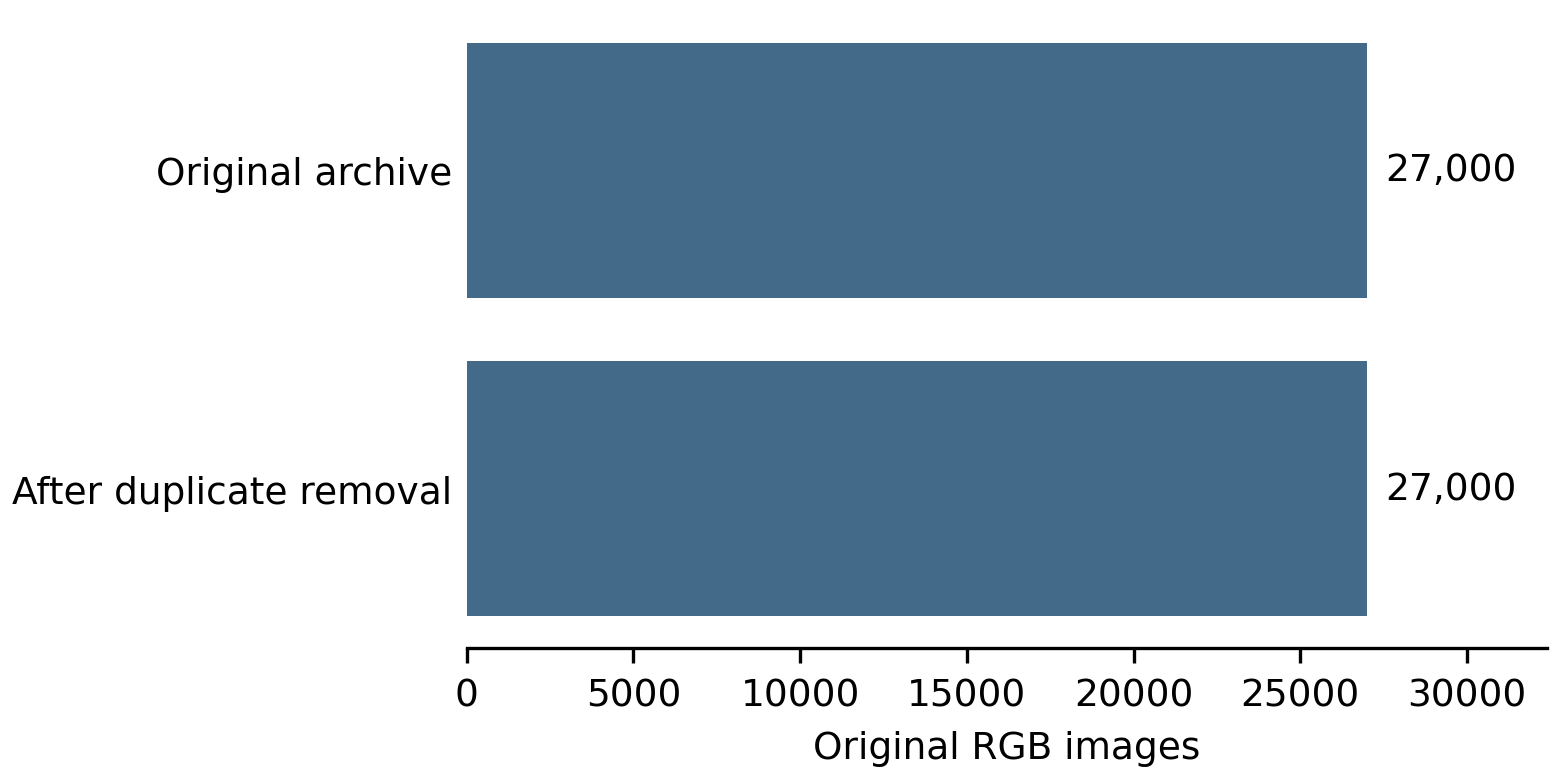

**Figure 1. Data cleaning audit.** Archive originals versus retained images after exact-pixel duplicate removal. No duplicates are fabricated for illustration.

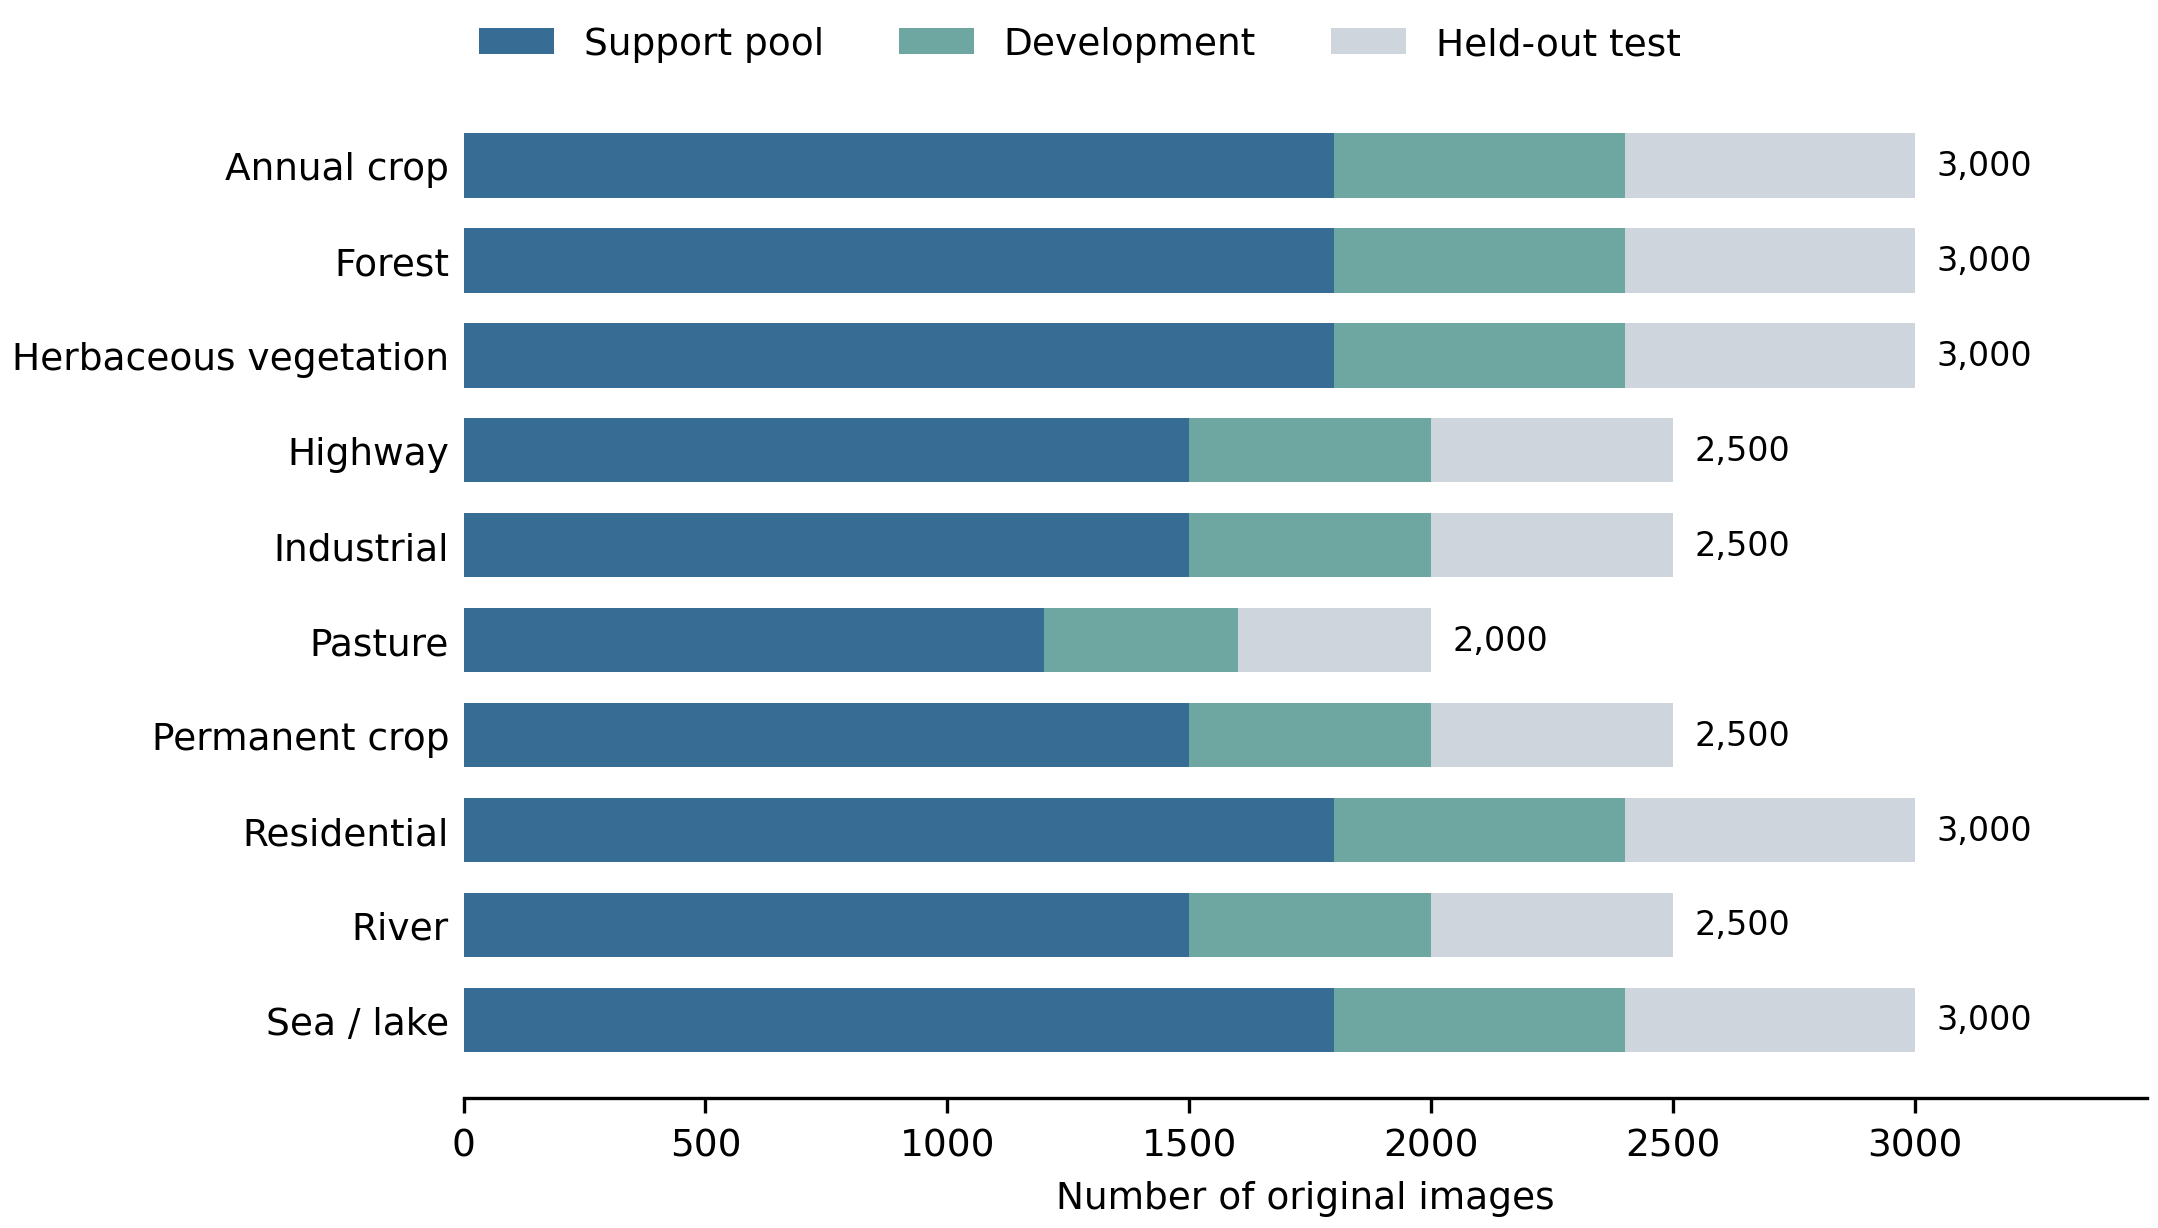

**Figure 2. Class balance and partitions.** Original image counts by class, divided into support, development and held-out test partitions.

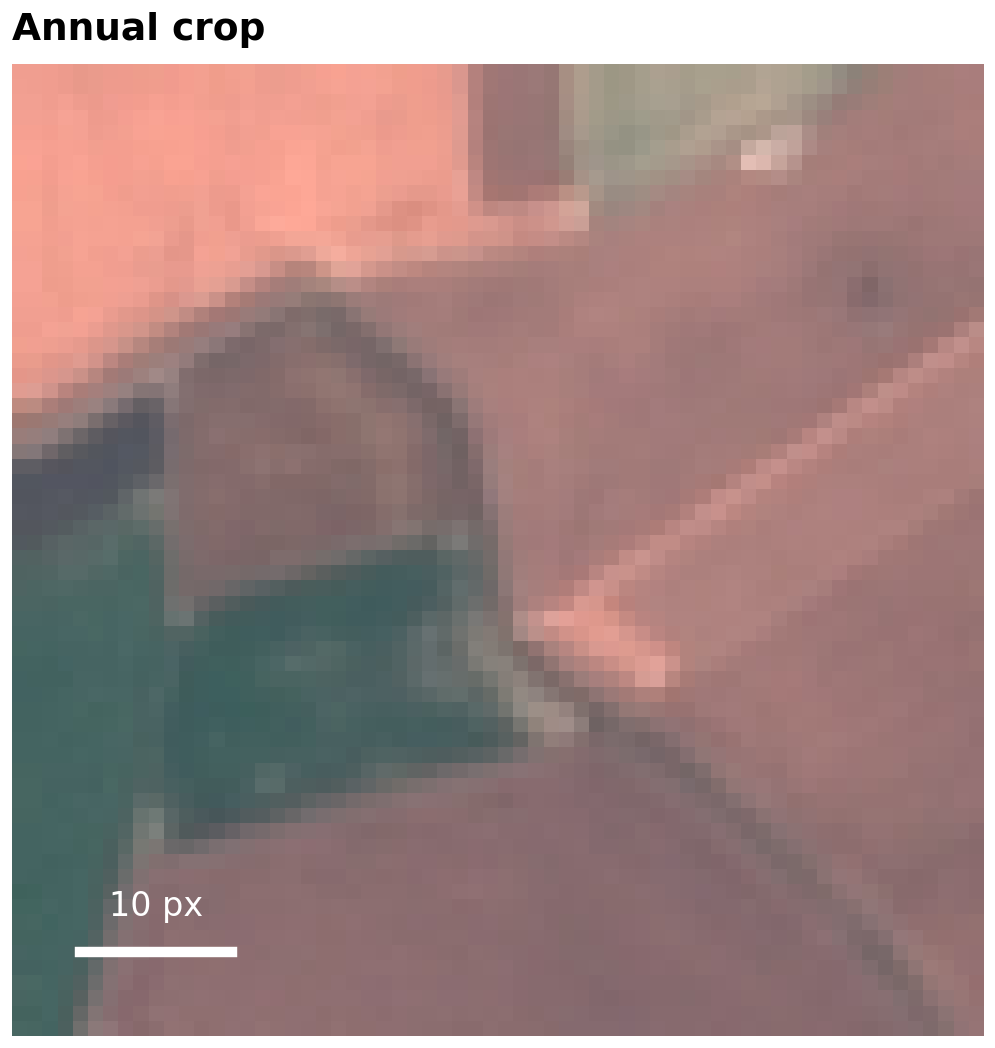

**Figure 3. One labeled EuroSAT image.** Native RGB tile from the annual-crop support pool. The scale marker is in pixels, not geographical distance.

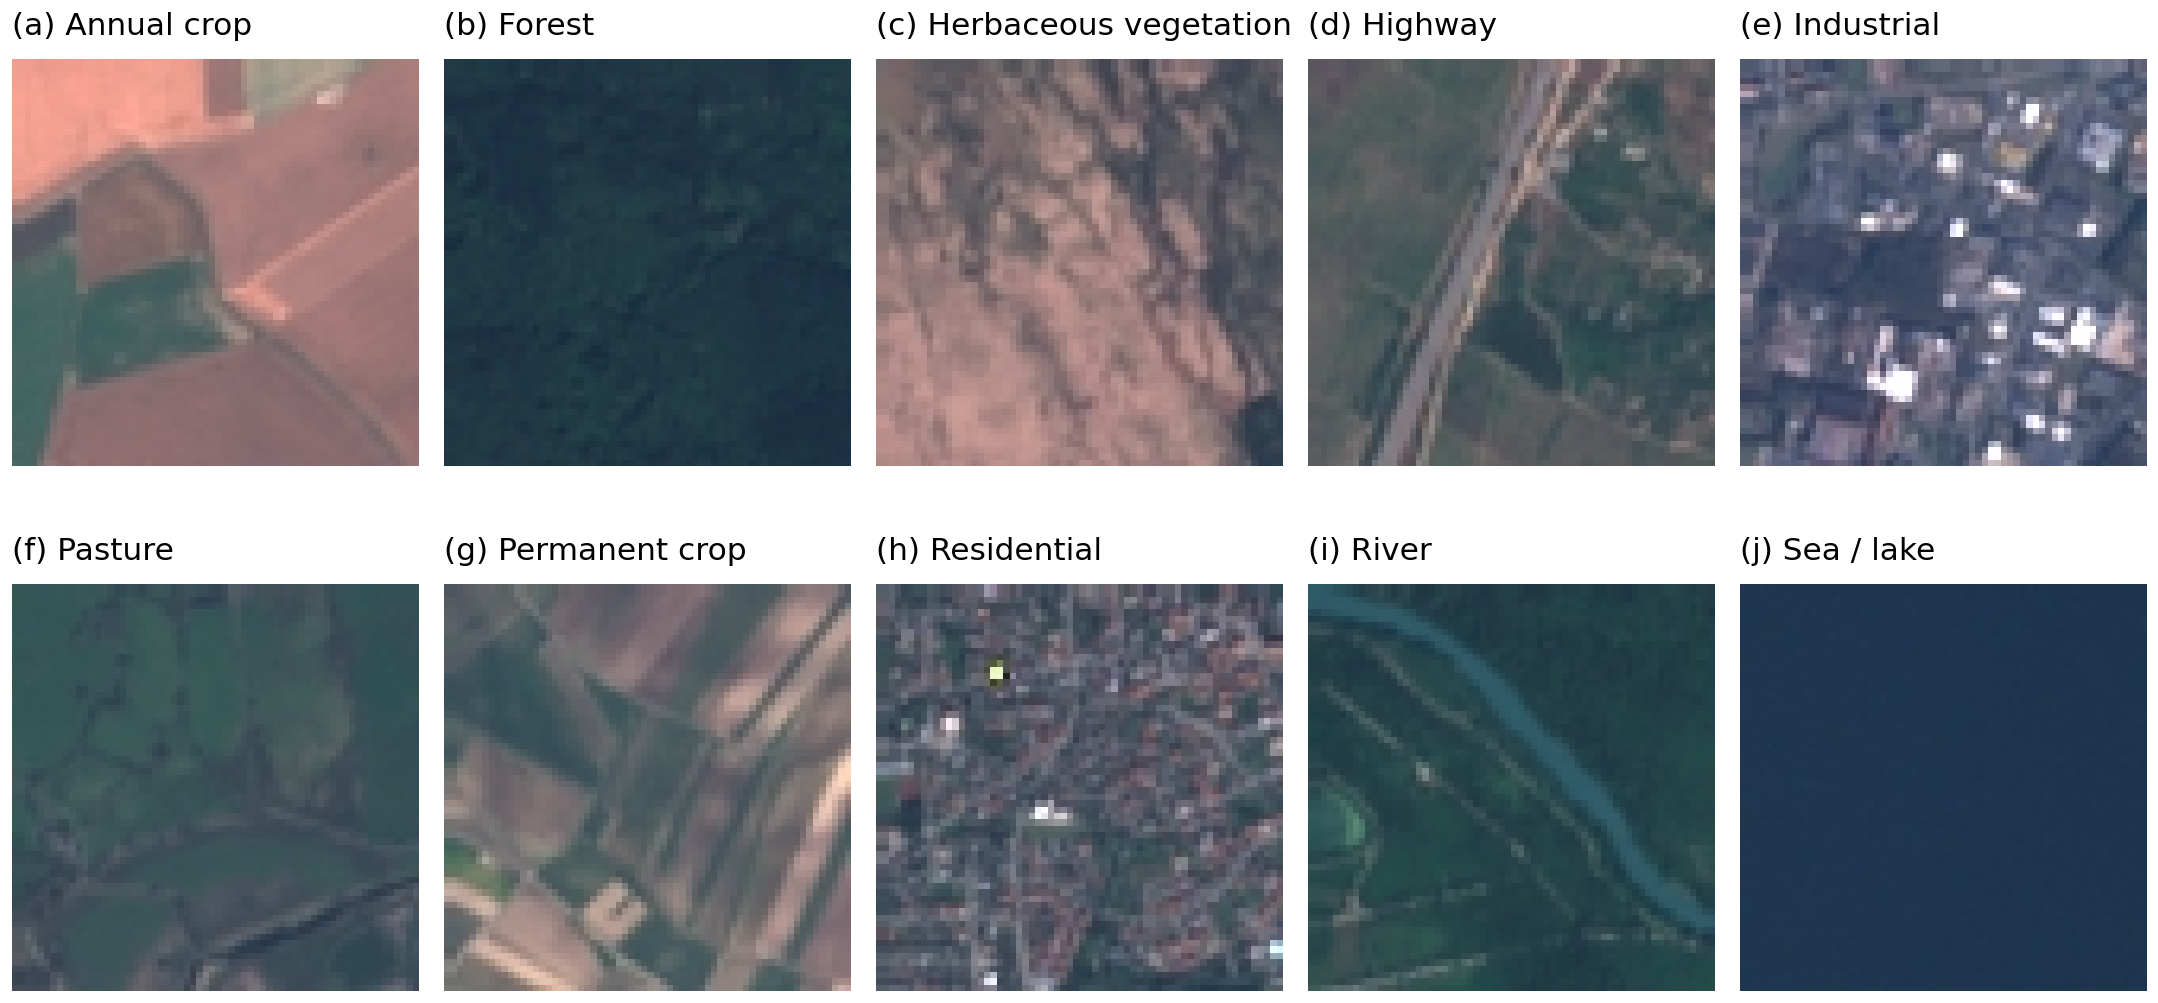

**Figure 4. Examples of all ten classes.** Unaugmented native RGB tiles sampled from the support pool with a fixed seed.

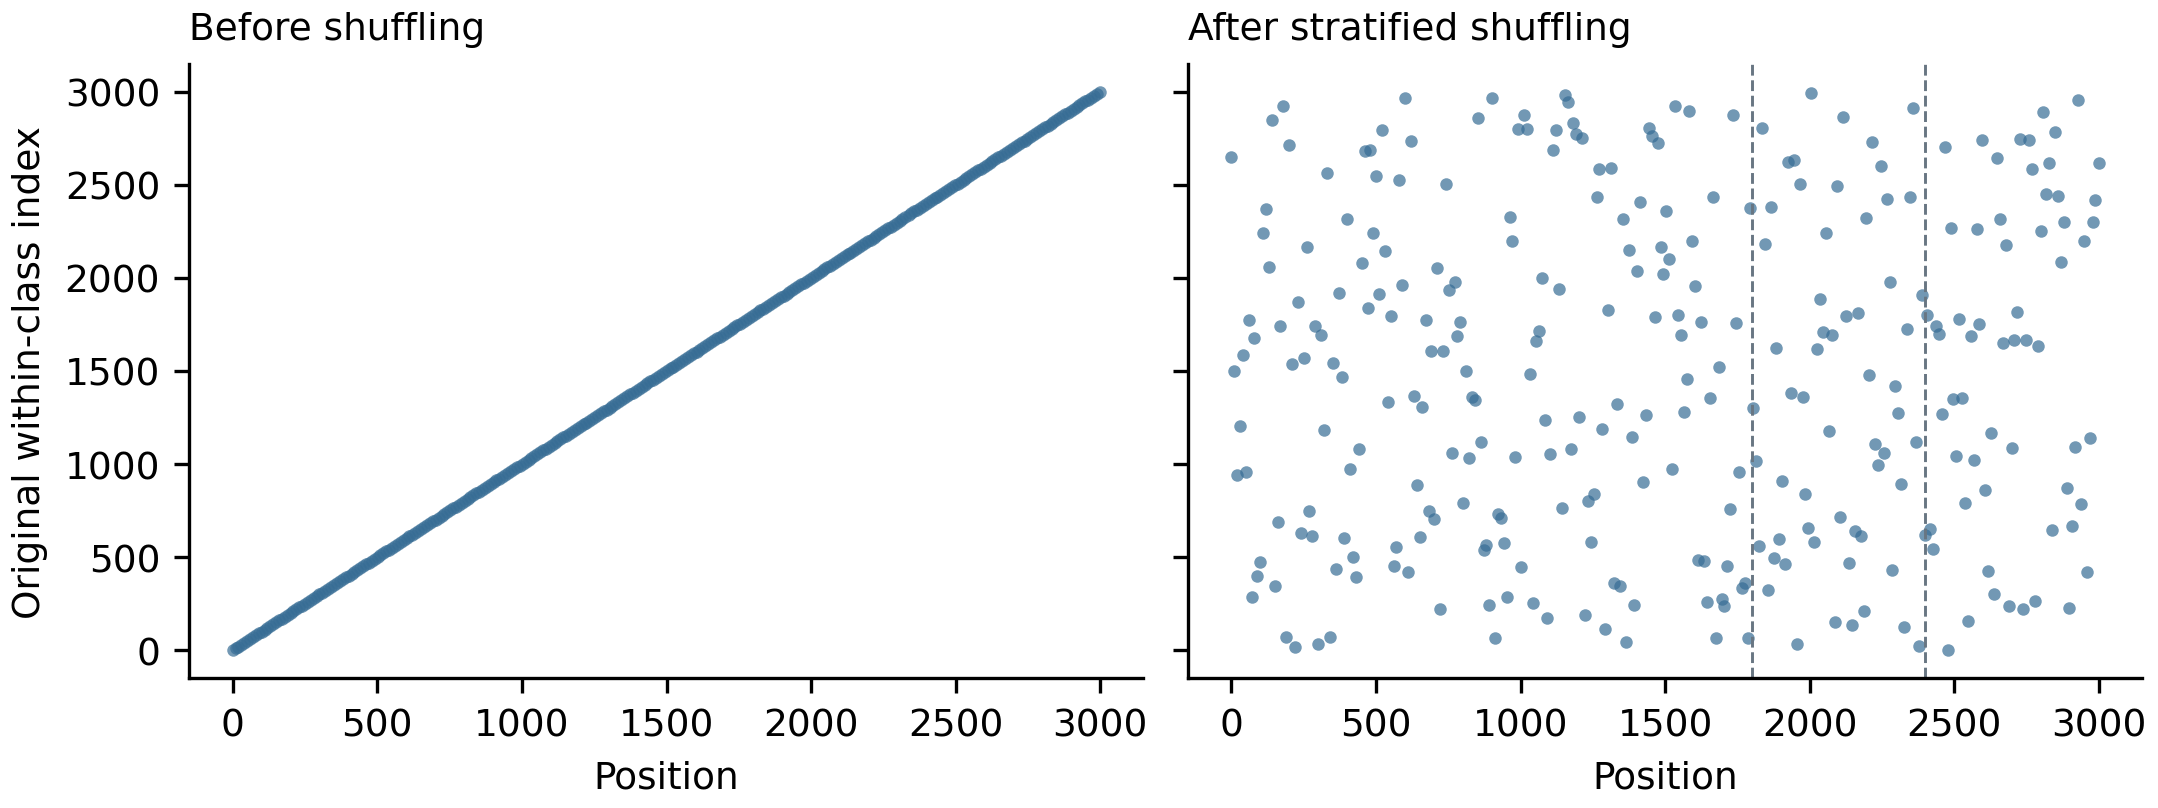

**Figure 5. Actual stratified shuffling.** The annual-crop class is shown before and after the permutation used for the split. Dashed boundaries mark support/development/test partitions; at most 300 evenly spaced positions are plotted. Every class uses the same procedure.

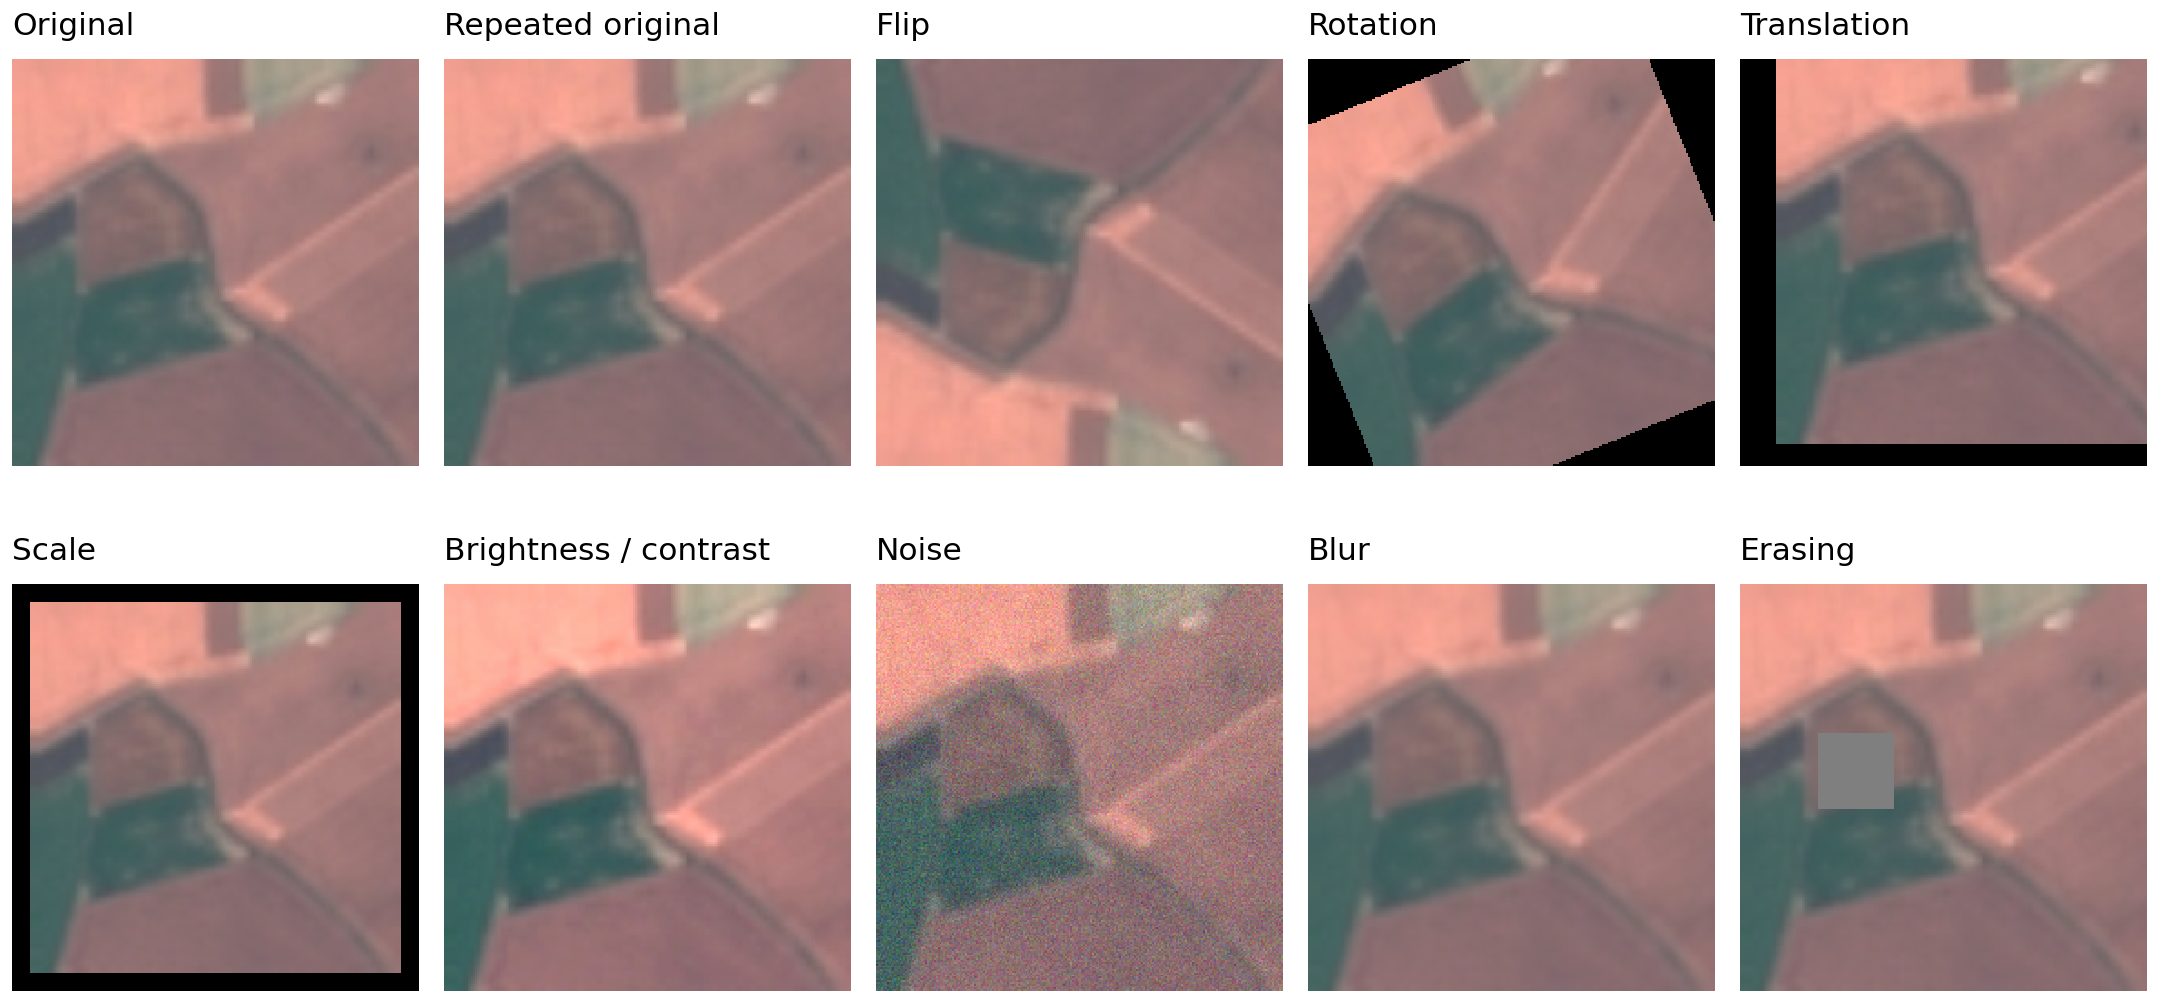

**Figure 6. Support-image augmentation policies.** One original support image, processed at 224 × 224, shown under the baseline, repeated-original control and individual augmentation methods. These views do not add labeled original shots.

Tables, 300-DPI PNGs, PDFs and image-source manifests: /content/drive/MyDrive/ColabNotebooks/cs7643/EuroSATLowData/outputs/dataset/49e02e45e1ef9f12e484ee23d5372cd1bb422c9e496e151835b9348eb5ad3b79


In [27]:
import pandas as pd
from IPython.display import display, Markdown, Image as NotebookImage

dataset = explore(STORAGE, SCRATCH, config)
profile = dataset['profile']
display(pd.DataFrame({
    'Measure': ['Original images', 'Retained unique images', 'Classes', 'Native image sizes',
                'Color modes', 'Duplicates removed', 'Corrupt images', 'Cross-split image overlap',
                'Cross-split pixel overlap', 'Experiment scope'],
    'Value': [profile['original_images'], profile['images'], profile['classes'],
              str(profile['native_sizes']), str(profile['color_modes']), profile['duplicates_removed'],
              profile['corrupt_images'], profile['partition_overlap_images'],
              profile['partition_overlap_pixels'], MODE]
}))
display(pd.DataFrame(profile['class_counts']).set_index('class'))
captions = [
    ('cleaning_audit', '**Figure 1. Data cleaning audit.** Archive originals versus retained images after exact-pixel duplicate removal. No duplicates are fabricated for illustration.'),
    ('class_distribution', '**Figure 2. Class balance and partitions.** Original image counts by class, divided into support, development and held-out test partitions.'),
    ('example_tile', '**Figure 3. One labeled EuroSAT image.** Native RGB tile from the annual-crop support pool. The scale marker is in pixels, not geographical distance.'),
    ('class_examples', '**Figure 4. Examples of all ten classes.** Unaugmented native RGB tiles sampled from the support pool with a fixed seed.'),
    ('stratified_shuffle', '**Figure 5. Actual stratified shuffling.** The annual-crop class is shown before and after the permutation used for the split. Dashed boundaries mark support/development/test partitions; at most 300 evenly spaced positions are plotted. Every class uses the same procedure.'),
    ('augmentation_examples', '**Figure 6. Support-image augmentation policies.** One original support image, processed at 224 × 224, shown under the baseline, repeated-original control and individual augmentation methods. These views do not add labeled original shots.')
]
for name, caption in captions:
    display(NotebookImage(filename=dataset['figures'][name]['png'], width=360 if name == 'example_tile' else 820))
    display(Markdown(caption))
print('Tables, 300-DPI PNGs, PDFs and image-source manifests:', dataset['output'])


## 6. Four-person implementation map

Choose one primary owner and one reviewer for each part. Every model owner runs the **same complete policy grid** on their own backbone; augmentation ownership below concerns implementation and review, not omitting conditions. The proposal's comparisons require shared splits, original support images, query images, strengths, classifier rules and seeds.

Set `ASSIGNMENT` in section 1 to a backbone name to run only that model. The configuration cells in Parts A–D only prepare objects; they do not start experiments. Implement reusable behavior in the linked source files, rebuild this notebook, and use a pull request. Check completed work off here and in `TODO.md`.


### Part A — Shared data protocol and ResNet-18 baseline

**Suggested owner:** teammate 1 · **Reviewer:** teammate 4

Implementation: [`data.py`](src/eurosat/data.py), [`runtime.py`](src/eurosat/runtime.py), [`models.py`](src/eurosat/models.py), [`exploration.py`](src/eurosat/exploration.py).

- [x] Verified RGB archive, decoded-pixel duplicate checks and class labels.
- [x] Stratified 60/20/20 partitions and nested, paired 1/5/10-shot support sets.
- [x] Frozen ResNet-18 adapter and full-dataset EDA figures.
- [ ] Agree on and freeze the shared dataset/seed/protocol manifest.
- [ ] Complete the full ResNet grid and export `results.json`.
- [ ] Have a second teammate verify data isolation and reproducibility.
- [ ] Resolve geographic-grouping feasibility or document the limitation.


In [28]:
# Part A implementation TODO: make shared-protocol changes in data.py/config.py,
# and the ResNet representation adapter in models.py. Do not change test partitions here.
# Set ASSIGNMENT = 'resnet18' in section 1 for this teammate's execution.
part_a_config = replace(config, models=['resnet18'])
print('Part A:', part_a_config.models)


Part A: ['resnet18']


### Part B — ConvNeXt-Tiny and geometric augmentation validation

**Suggested owner:** teammate 2 · **Reviewer:** teammate 1

Implementation: [`models.py`](src/eurosat/models.py), [`augment.py`](src/eurosat/augment.py), [`features.py`](src/eurosat/features.py).

- [x] ImageNet-1K ConvNeXt-Tiny, pooled features and final checkpoint normalization.
- [x] Flip, rotation, translation and scaling policies with deterministic image/view seeds.
- [ ] Review geometric strengths using development data; freeze choices before test reporting.
- [ ] Complete the full ConvNeXt grid, including every non-geometric control/condition.
- [ ] Report paired gains and compare modern-CNN versus ResNet representations.
- [ ] Review the shared split and augmentation-view manifests with Part A.


In [29]:
# Part B implementation TODO: geometric transforms belong in augment.py;
# ConvNeXt feature extraction belongs in models.py. Reuse the common classifier.
# Set ASSIGNMENT = 'convnext_tiny' in section 1 to execute this model only.
part_b_config = replace(config, models=['convnext_tiny'])
print('Part B:', part_b_config.models)


Part B: ['convnext_tiny']


### Part C — ViT-B/16 and color/pixel augmentation validation

**Suggested owner:** teammate 3 · **Reviewer:** teammate 2

Implementation: [`models.py`](src/eurosat/models.py), [`augment.py`](src/eurosat/augment.py), [`features.py`](src/eurosat/features.py).

- [x] ImageNet-1K ViT-B/16 final normalized class-token representation.
- [x] Brightness/contrast, noise, blur and erasing conditions, with support-only augmentation.
- [ ] Confirm preprocessing, feature dimensions and frozen evaluation behavior.
- [ ] Review policy strengths on development data; keep views identical across models.
- [ ] Complete the full ViT grid and export paired comparisons with both CNNs.
- [ ] Prespecify selected 1-shot nine-view comparisons; cutout remains optional.


In [30]:
# Part C implementation TODO: color/noise/blur/erasing policies belong in augment.py;
# ViT representation extraction belongs in models.py. Keep original shot budgets unchanged.
# Set ASSIGNMENT = 'vit_b_16' in section 1 to execute this model only.
part_c_config = replace(config, models=['vit_b_16'])
print('Part C:', part_c_config.models)


Part C: ['vit_b_16']


### Part D — DINOv2, statistical summaries and report integration

**Suggested owner:** teammate 4 · **Reviewer:** teammate 3

Implementation: [`models.py`](src/eurosat/models.py), [`evaluation.py`](src/eurosat/evaluation.py), [`reporting.py`](src/eurosat/reporting.py).

- [x] Official pinned DINOv2 ViT-S/14 checkpoint and frozen class-token features.
- [x] Common logistic regression, Macro-F1, recall, confusion matrices and paired gains.
- [ ] Complete the full DINOv2 grid and validate checkpoint/software provenance.
- [ ] Merge compatible model exports and check trial completeness/paired comparisons.
- [ ] Prepare model-by-shot, augmentation-gain and class-level result figures.
- [ ] Report development-label use, timing conditions, negative findings and pretraining confounds.
- [ ] Coordinate final methods, limitations and citations; do not attribute DINOv2/ViT differences to self-supervision alone.


In [31]:
# Part D implementation TODO: keep metric/classifier rules in evaluation.py;
# combine completed exports through reporting.py rather than hand-editing CSVs.
# Set ASSIGNMENT = 'dinov2_vits14' in section 1 to execute this model only.
part_d_config = replace(config, models=['dinov2_vits14'])
print('Part D:', part_d_config.models)


Part D: ['dinov2_vits14']


## 7. Run or resume the selected experiment

Only support images receive random augmentation. Development and test preprocessing are deterministic. Feature extraction is cached in chunks, classifier parameters are stored as numeric checkpoints, and completed trials are skipped. This cell does not repeat dataset cleaning or GPU work that has already completed for the same configuration.


In [32]:
results = run(config, STORAGE, SCRATCH, target=TARGET)


Compute: Tesla T4 [cuda] — device check passed
Data: 400 unique images, splits {'support': 240, 'dev': 80, 'test': 80}; 0 exact-pixel duplicates removed
Completed results reused: resnet18
Finished. Results: /content/drive/MyDrive/ColabNotebooks/cs7643/EuroSATLowData/outputs/aad611a699bf3c757541bc5ebf0521905a46bc16eb84ce1e5fda37f48b2fff37


## 8. Results and reporting

Accuracy and Macro-F1 are fractions; paired improvements are percentage points relative to each trial's unaugmented baseline. Preferred policies are selected from development performance, while all prespecified comparisons remain available in the exported results. Smoke scores below validate execution only.


In [33]:
table = pd.DataFrame(results['summary'])
display(table.sort_values(['model', 'shots', 'policy']).reset_index(drop=True).round(3))
print('Results, classifier records and development-selected policies:', results['output'])


,model,policy,shots,trials,accuracy,accuracy_std,macro_f1,paired_gain_percentage_points,dev_accuracy
0,resnet18,flip,1,1,0.500,0.0,0.447,-3.75,0.525
1,resnet18,none,1,1,0.538,0.0,0.498,0.00,0.538
2,resnet18,repeat,1,1,0.525,0.0,0.473,-1.25,0.575
3,resnet18,flip,5,1,0.775,0.0,0.771,5.00,0.825
4,resnet18,none,5,1,0.725,0.0,0.707,0.00,0.812
5,resnet18,repeat,5,1,0.750,0.0,0.736,2.50,0.812
6,resnet18,flip,10,1,0.788,0.0,0.785,-2.50,0.775
7,resnet18,none,10,1,0.812,0.0,0.802,0.00,0.800
8,resnet18,repeat,10,1,0.812,0.0,0.812,0.00,0.812


Results, classifier records and development-selected policies: /content/drive/MyDrive/ColabNotebooks/cs7643/EuroSATLowData/outputs/aad611a699bf3c757541bc5ebf0521905a46bc16eb84ce1e5fda37f48b2fff37
